# Demo: predicting NYC taxi trip duration

A hands-on tour of the final model from this repo: train it, ask it about real routes, and see what drives its predictions.

- Data: April 2026 NYC TLC yellow taxi trips (run `python scripts/download_data.py 2026-04` first).
- Model: the CV-selected LightGBM (raw seconds, L2, zone geometry, recency weights with a 7-day half-life, 600 trees),
  trained on the same 500,000-trip sample as in `scripts/final_eval.py`.
- Honest accuracy numbers live in [`reports/final_results.md`](../reports/final_results.md); this notebook is for intuition, not evaluation.

In [1]:
import sys, time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from taxi import config, data, features, models, zones as zmod

assert config.trip_file(config.TRAIN_MONTH).exists(), "run: python scripts/download_data.py 2026-04"
zones = zmod.load_zones()

## 1. Train the final model

In [2]:
train, _ = data.load_clean(config.TRAIN_MONTH, max_rows=config.MAX_TRAIN_ROWS)
X = features.build_features(train, zones)
y = train["duration_s"].to_numpy("float64")

t0 = time.time()
model = models.LGBMModel("raw", "regression", n_estimators=600, recency_halflife_days=7)
model.fit(X, y, sample_weight=models.recency_weights(train["pickup"], 7))
baseline = models.RouteHourMedian(5).fit(X, y)
print(f"trained on {len(train):,} trips in {time.time() - t0:.0f} s")

trained on 500,000 trips in 19 s


## 2. Ask the model about real trips

`predict_trip` builds a one-row trip with only pickup-time information (zones, time, passengers) and returns minutes.
The route-hour median baseline is shown next to it for comparison.

In [3]:
def zone_id(name: str) -> int:
    hits = zones.index[zones["Zone"] == name]
    if len(hits) != 1:
        raise KeyError(name)
    return int(hits[0])


def trips_frame(rows) -> pd.DataFrame:
    return pd.DataFrame({
        "pickup": pd.to_datetime([r[2] for r in rows]),
        "vendor": 2,
        "passenger_count": 1.0,
        "pu": [zone_id(r[0]) for r in rows],
        "do": [zone_id(r[1]) for r in rows],
    })


examples = [
    ("Midtown Center", "JFK Airport", "2026-05-06 08:00"),
    ("Midtown Center", "JFK Airport", "2026-05-06 03:00"),
    ("Midtown Center", "JFK Airport", "2026-05-10 08:00"),
    ("Times Sq/Theatre District", "Financial District North", "2026-05-06 17:30"),
    ("Upper East Side North", "East Village", "2026-05-06 13:00"),
    ("LaGuardia Airport", "Times Sq/Theatre District", "2026-05-08 18:00"),
    ("Williamsburg (North Side)", "Park Slope", "2026-05-09 23:00"),
    ("Astoria", "Astoria", "2026-05-06 10:00"),
]
q = trips_frame(examples)
Xq = features.build_features(q, zones)
pd.DataFrame({
    "from": [e[0] for e in examples],
    "to": [e[1] for e in examples],
    "pickup": q["pickup"].dt.strftime("%a %H:%M"),
    "model, min": (model.predict(Xq) / 60).round(1),
    "baseline, min": (baseline.predict(Xq) / 60).round(1),
})

,from,to,pickup,"model, min","baseline, min"
0,Midtown Center,JFK Airport,Wed 08:00,58.9,45.1
1,Midtown Center,JFK Airport,Wed 03:00,32.8,58.0
2,Midtown Center,JFK Airport,Sun 08:00,30.0,45.1
3,Times Sq/Theatre District,Financial District North,Wed 17:30,37.0,33.8
4,Upper East Side North,East Village,Wed 13:00,28.6,23.5
5,LaGuardia Airport,Times Sq/Theatre District,Fri 18:00,50.7,37.7
6,Williamsburg (North Side),Park Slope,Sat 23:00,26.3,23.6
7,Astoria,Astoria,Wed 10:00,7.4,4.8


The same Midtown to JFK ride is predicted very differently at 8 am on a Wednesday, at 3 am, and on a Sunday morning.
The model learned this from zones and time of day alone; it has no live traffic data.
The baseline is jumpy here because many (route, hour) cells have fewer than 5 April trips, so it falls back to coarser medians.

## 3. One route across the day

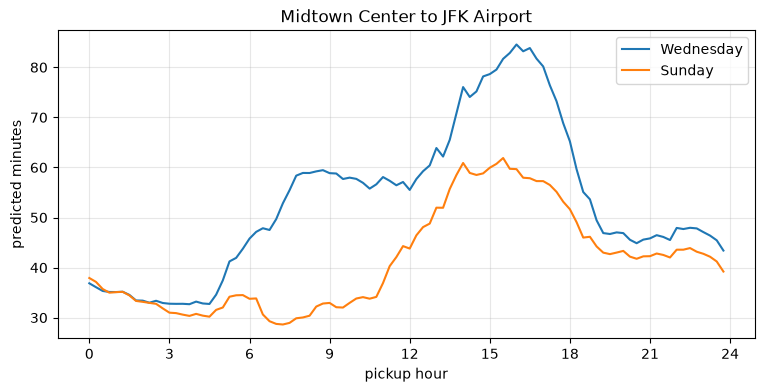

In [4]:
hours = pd.date_range("2026-05-06 00:00", periods=96, freq="15min")
fig, ax = plt.subplots(figsize=(9, 4))
for day, label in [("2026-05-06", "Wednesday"), ("2026-05-10", "Sunday")]:
    times = hours + (pd.Timestamp(day) - pd.Timestamp("2026-05-06"))
    rows = [("Midtown Center", "JFK Airport", t) for t in times]
    p = model.predict(features.build_features(trips_frame(rows), zones)) / 60
    ax.plot(hours.hour + hours.minute / 60, p, label=label)
ax.set(xlabel="pickup hour", ylabel="predicted minutes", title="Midtown Center to JFK Airport", xticks=range(0, 25, 3))
ax.grid(alpha=0.3)
ax.legend();

## 4. What the model relies on

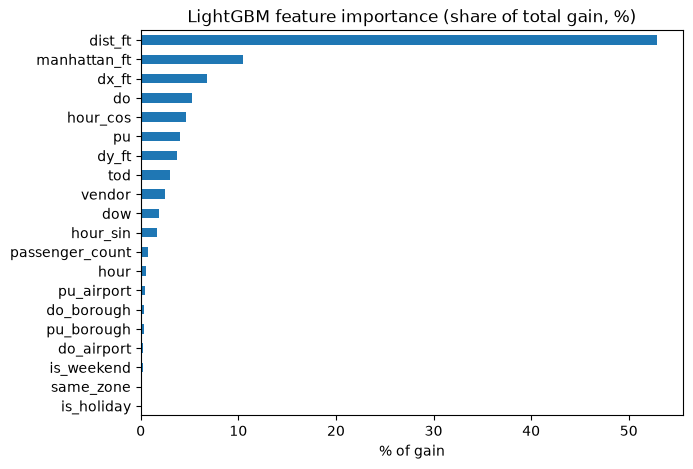

In [5]:
imp = model.feature_importance().sort_values()
imp = imp / imp.sum() * 100
ax = imp.plot.barh(figsize=(7, 5), title="LightGBM feature importance (share of total gain, %)")
ax.set_xlabel("% of gain");

Geometry dominates: straight-line distance between zone centroids alone takes about half of the gain, and the other
geometry features add roughly another fifth. Zone identities and time of day then refine that estimate (traffic patterns,
specific routes), which is how the model tells a 3 am airport run from a rush-hour one.

## Limits

- Point estimates only; real trips scatter widely around them, especially long and airport trips (see `reports/error_analysis.md`).
- Trained on one month (April 2026); holidays and seasonal changes are not learned.
- No traffic, weather or event data.